In [42]:
!pip install -q spacy nltk

In [43]:
import nltk
import spacy
import heapq
import string

import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from string import punctuation
from heapq import nlargest

In [44]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

!python -m spacy download en_core_web_sm

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 79.3 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [45]:
nlp = spacy.load('en_core_web_sm')

print("SpaCy model loaded successfully!")

SpaCy model loaded successfully!


In [46]:
text = """
The Orbiter Discovery, OV-103, is considered eligible for listing in the National Register of Historic Places (NRHP) in the context of the U.S. Space Shuttle Program (1969-2011) under Criterion A in the areas of Space Exploration and Transportation and under Criterion C in the area of Engineering. Because it has achieved significance within the past fifty years, Criteria Consideration G applies. Under Criterion A, Discovery is significant as the oldest of the three extant orbiter vehicles constructed for the Space Shuttle Program (SSP), the longest running American space program to date; she was the third of five orbiters built by NASA. Unlike the Mercury, Gemini, and Apollo programs, the SSP’s emphasis was on cost effectiveness and reusability, and eventually the construction of a space station. Including her maiden voyage (launched August 30, 1984), Discovery flew to space thirty-nine times, more than any of the other four orbiters; she was also the first orbiter to fly twenty missions. She had the honor of being chosen as the Return to Flight vehicle after both the Challenger and Columbia accidents. Discovery was the first shuttle to fly with the redesigned SRBs, a result of the Challenger accident, and the first shuttle to fly with the Phase II and Block I SSME. Discovery also carried the Hubble Space Telescope to orbit and performed two of the five servicing missions to the observatory. She flew the first and last dedicated Department of Defense (DoD) missions, as well as the first unclassified defense-related mission. In addition, Discovery was vital to the construction of the International Space Station (ISS); she flew thirteen of the thirty-seven total missions flown to the station by a U.S. Space Shuttle. She was the first orbiter to dock to the ISS, and the first to perform an exchange of a resident crew. Under Criterion C, Discovery is significant as a feat of engineering. According to Wayne Hale, a flight director from Johnson Space Center, the Space Shuttle orbiter represents a “huge technological leap from expendable rockets and capsules to a reusable, winged, hypersonic, cargo-carrying spacecraft.” Although her base structure followed a conventional aircraft design, she used advanced materials that both minimized her weight for cargo-carrying purposes and featured low thermal expansion ratios, which provided a stable base for her Thermal Protection System (TPS) materials. The Space Shuttle orbiter also featured the first reusable TPS; all previous spaceflight vehicles had a single-use, ablative heat shield. Other notable engineering achievements of the orbiter included the first reusable orbital propulsion system, and the first two-fault-tolerant Integrated Avionics System. As Hale stated, the Space Shuttle remains “the largest, fastest, winged hypersonic aircraft in history,” having regularly flown at twenty-five times the speed of sound.
"""

print("Кількість символів:", len(text))
print("Кількість слів:", len(text.split()))

Кількість символів: 2908
Кількість слів: 448


In [47]:
sentences = sent_tokenize(text)

print("Кількість речень:", len(sentences))

for i, sentence in enumerate(sentences, 1):
    print(f"{i}. {sentence}\n")

Кількість речень: 16
1. 
The Orbiter Discovery, OV-103, is considered eligible for listing in the National Register of Historic Places (NRHP) in the context of the U.S. Space Shuttle Program (1969-2011) under Criterion A in the areas of Space Exploration and Transportation and under Criterion C in the area of Engineering.

2. Because it has achieved significance within the past fifty years, Criteria Consideration G applies.

3. Under Criterion A, Discovery is significant as the oldest of the three extant orbiter vehicles constructed for the Space Shuttle Program (SSP), the longest running American space program to date; she was the third of five orbiters built by NASA.

4. Unlike the Mercury, Gemini, and Apollo programs, the SSP’s emphasis was on cost effectiveness and reusability, and eventually the construction of a space station.

5. Including her maiden voyage (launched August 30, 1984), Discovery flew to space thirty-nine times, more than any of the other four orbiters; she was al

In [48]:
stop_words = set(stopwords.words('english'))

# Додаємо пунктуацію до стоп-символів
punctuation_set = set(string.punctuation)

# Токенізація слів
words = word_tokenize(text.lower())

# Видалення стоп-слів та пунктуації
filtered_words = [
    word for word in words
    if word not in stop_words
    and word not in punctuation_set
    and word.isalpha()
]

print("Початкова кількість слів:", len(words))
print("Кількість слів після очищення:", len(filtered_words))

print(filtered_words[:30])

Початкова кількість слів: 519
Кількість слів після очищення: 259
['orbiter', 'discovery', 'considered', 'eligible', 'listing', 'national', 'register', 'historic', 'places', 'nrhp', 'context', 'space', 'shuttle', 'program', 'criterion', 'areas', 'space', 'exploration', 'transportation', 'criterion', 'c', 'area', 'engineering', 'achieved', 'significance', 'within', 'past', 'fifty', 'years', 'criteria']


In [49]:
word_frequencies = Counter(filtered_words)

print("Найчастіші слова:")

for word, frequency in word_frequencies.most_common(15):
    print(f"{word}: {frequency}")

Найчастіші слова:
space: 13
first: 10
shuttle: 8
orbiter: 7
discovery: 7
criterion: 4
missions: 4
program: 3
engineering: 3
station: 3
flew: 3
also: 3
fly: 3
reusable: 3
system: 3


In [50]:
max_frequency = max(word_frequencies.values())

for word in word_frequencies:
    word_frequencies[word] /= max_frequency

In [51]:
sentence_scores = {}

for sentence in sentences:
    sentence_words = word_tokenize(sentence.lower())

    for word in sentence_words:
        if word in word_frequencies:
            if len(sentence_words) < 40:
                sentence_scores[sentence] = (
                    sentence_scores.get(sentence, 0)
                    + word_frequencies[word]
                )

print("Оцінки речень:")

for sentence, score in sentence_scores.items():
    print(f"{score:.3f} — {sentence[:100]}...")

Оцінки речень:
0.769 — Because it has achieved significance within the past fifty years, Criteria Consideration G applies....
2.308 — Unlike the Mercury, Gemini, and Apollo programs, the SSP’s emphasis was on cost effectiveness and re...
4.692 — Including her maiden voyage (launched August 30, 1984), Discovery flew to space thirty-nine times, m...
0.769 — She had the honor of being chosen as the Return to Flight vehicle after both the Challenger and Colu...
4.538 — Discovery was the first shuttle to fly with the redesigned SRBs, a result of the Challenger accident...
2.846 — Discovery also carried the Hubble Space Telescope to orbit and performed two of the five servicing m...
2.692 — She flew the first and last dedicated Department of Defense (DoD) missions, as well as the first unc...
5.000 — In addition, Discovery was vital to the construction of the International Space Station (ISS); she f...
2.615 — She was the first orbiter to dock to the ISS, and the first to perform an exchange

In [52]:
select_length = max(
    1,
    int(len(sentences) * 0.3)
)

summary_sentences = nlargest(
    select_length,
    sentence_scores,
    key=sentence_scores.get
)

# Відновлюємо початковий порядок речень
summary_sentences = [
    sentence for sentence in sentences
    if sentence in summary_sentences
]

summary_nltk = ' '.join(summary_sentences)

print("SUMMARY USING NLTK:\n")
print(summary_nltk)

SUMMARY USING NLTK:

Including her maiden voyage (launched August 30, 1984), Discovery flew to space thirty-nine times, more than any of the other four orbiters; she was also the first orbiter to fly twenty missions. Discovery was the first shuttle to fly with the redesigned SRBs, a result of the Challenger accident, and the first shuttle to fly with the Phase II and Block I SSME. In addition, Discovery was vital to the construction of the International Space Station (ISS); she flew thirteen of the thirty-seven total missions flown to the station by a U.S. Space Shuttle. The Space Shuttle orbiter also featured the first reusable TPS; all previous spaceflight vehicles had a single-use, ablative heat shield.


In [53]:
original_words = len(word_tokenize(text))
summary_words = len(word_tokenize(summary_nltk))

compression = (
    1 - summary_words / original_words
) * 100

print("Original words:", original_words)
print("Summary words:", summary_words)
print(f"Compression: {compression:.2f}%")

Original words: 519
Summary words: 132
Compression: 74.57%


In [54]:
doc = nlp(text)

# Отримуємо токени після лематизації
filtered_lemmas = [
    token.lemma_.lower()
    for token in doc
    if not token.is_stop
    and not token.is_punct
    and not token.is_space
    and token.is_alpha
]

print("Кількість лем:", len(filtered_lemmas))
print(filtered_lemmas[:40])

Кількість лем: 248
['orbiter', 'discovery', 'consider', 'eligible', 'list', 'national', 'register', 'historic', 'places', 'nrhp', 'context', 'space', 'shuttle', 'program', 'criterion', 'area', 'space', 'exploration', 'transportation', 'criterion', 'c', 'area', 'engineering', 'achieve', 'significance', 'past', 'year', 'criteria', 'consideration', 'g', 'apply', 'criterion', 'discovery', 'significant', 'old', 'extant', 'orbiter', 'vehicle', 'construct', 'space']


In [55]:
word_frequencies_spacy = Counter(filtered_lemmas)

print("Найчастіші леми:")

for word, frequency in word_frequencies_spacy.most_common(15):
    print(f"{word}: {frequency}")

Найчастіші леми:
space: 13
orbiter: 9
shuttle: 8
fly: 8
discovery: 7
mission: 5
program: 4
criterion: 4
engineering: 3
vehicle: 3
station: 3
carry: 3
reusable: 3
system: 3
area: 2


In [56]:
max_frequency_spacy = max(
    word_frequencies_spacy.values()
)

for word in word_frequencies_spacy:
    word_frequencies_spacy[word] /= max_frequency_spacy

In [57]:
spacy_sentences = list(doc.sents)

sentence_scores_spacy = {}

for sentence in spacy_sentences:

    score = 0

    for token in sentence:
        lemma = token.lemma_.lower()

        if lemma in word_frequencies_spacy:
            score += word_frequencies_spacy[lemma]

    if len(sentence) < 40:
        sentence_scores_spacy[sentence.text] = score

print("Оцінки речень SpaCy:")

for sentence, score in sentence_scores_spacy.items():
    print(f"{score:.3f} — {sentence[:100]}...")

Оцінки речень SpaCy:
0.615 — Because it has achieved significance within the past fifty years, Criteria Consideration G applies....
2.538 — Unlike the Mercury, Gemini, and Apollo programs, the SSP’s emphasis was on cost effectiveness and re...
1.000 — She had the honor of being chosen as the Return to Flight vehicle after both the Challenger and Colu...
3.846 — Discovery was the first shuttle to fly with the redesigned SRBs, a result of the Challenger accident...
2.692 — Discovery also carried the Hubble Space Telescope to orbit and performed two of the five servicing m...
2.077 — She flew the first and last dedicated Department of Defense (DoD) missions, as well as the first unc...
6.154 — In addition, Discovery was vital to the construction of the International Space Station (ISS); she f...
1.308 — She was the first orbiter to dock to the ISS, and the first to perform an exchange of a resident cre...
1.462 — Under Criterion C, Discovery is significant as a feat of engineering....
3.6

In [58]:
select_length_spacy = max(
    1,
    int(len(spacy_sentences) * 0.3)
)

summary_spacy_sentences = nlargest(
    select_length_spacy,
    sentence_scores_spacy,
    key=sentence_scores_spacy.get
)

# Повертаємо речення до початкового порядку
summary_spacy_sentences = [
    sentence.text
    for sentence in spacy_sentences
    if sentence.text in summary_spacy_sentences
]

summary_spacy = ' '.join(summary_spacy_sentences)

print("SUMMARY USING SPACY:\n")
print(summary_spacy)

SUMMARY USING SPACY:

Discovery was the first shuttle to fly with the redesigned SRBs, a result of the Challenger accident, and the first shuttle to fly with the Phase II and Block I SSME. Discovery also carried the Hubble Space Telescope to orbit and performed two of the five servicing missions to the observatory. In addition, Discovery was vital to the construction of the International Space Station (ISS); she flew thirteen of the thirty-seven total missions flown to the station by a U.S. Space Shuttle. The Space Shuttle orbiter also featured the first reusable TPS; all previous spaceflight vehicles had a single-use, ablative heat shield. As Hale stated, the Space Shuttle remains “the largest, fastest, winged hypersonic aircraft in history,” having regularly flown at twenty-five times the speed of sound.



In [59]:
summary_spacy_words = len(
    word_tokenize(summary_spacy)
)

compression_spacy = (
    1 - summary_spacy_words / original_words
) * 100

print("Original words:", original_words)
print("Summary words:", summary_spacy_words)
print(f"Compression: {compression_spacy:.2f}%")

Original words: 519
Summary words: 146
Compression: 71.87%


In [60]:
results = pd.DataFrame({
    'Method': ['NLTK', 'SpaCy'],
    'Original words': [
        original_words,
        original_words
    ],
    'Summary words': [
        summary_words,
        summary_spacy_words
    ],
    'Compression (%)': [
        compression,
        compression_spacy
    ]
})

display(results)

,Method,Original words,Summary words,Compression (%)
0,NLTK,519,132,74.566474
1,SpaCy,519,146,71.868979


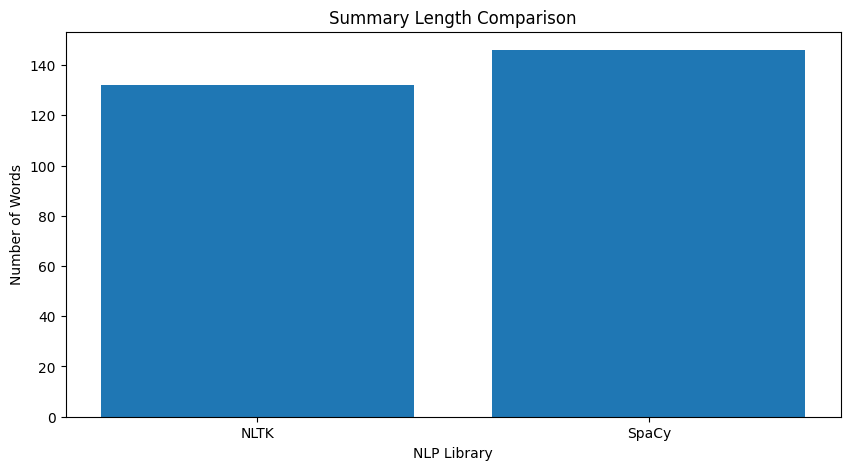

In [61]:
plt.figure(figsize=(10, 5))

plt.bar(
    results['Method'],
    results['Summary words']
)

plt.title('Summary Length Comparison')
plt.xlabel('NLP Library')
plt.ylabel('Number of Words')

plt.show()

In [62]:
print("=" * 60)
print("SUMMARY USING NLTK")
print("=" * 60)

print(summary_nltk)

print("\n" + "=" * 60)
print("SUMMARY USING SPACY")
print("=" * 60)

print(summary_spacy)

SUMMARY USING NLTK
Including her maiden voyage (launched August 30, 1984), Discovery flew to space thirty-nine times, more than any of the other four orbiters; she was also the first orbiter to fly twenty missions. Discovery was the first shuttle to fly with the redesigned SRBs, a result of the Challenger accident, and the first shuttle to fly with the Phase II and Block I SSME. In addition, Discovery was vital to the construction of the International Space Station (ISS); she flew thirteen of the thirty-seven total missions flown to the station by a U.S. Space Shuttle. The Space Shuttle orbiter also featured the first reusable TPS; all previous spaceflight vehicles had a single-use, ablative heat shield.

SUMMARY USING SPACY
Discovery was the first shuttle to fly with the redesigned SRBs, a result of the Challenger accident, and the first shuttle to fly with the Phase II and Block I SSME. Discovery also carried the Hubble Space Telescope to orbit and performed two of the five servicing

Обидва підходи є корисними для автоматичного аналізу великих текстів. При цьому SpaCy надає додаткові можливості лінгвістичного аналізу завдяки лематизації, а NLTK є зручним інструментом для базової обробки текстових даних.